# 07. Gráficos para la presentación

Este notebook arma los gráficos más claros para mostrar los resultados. **No calcula nada nuevo**: lee las tablas que ya guardaron los notebooks 03, 04 y 05 (`reports/tables/`) y dibuja cada estimación con su intervalo de confianza del 95 %.

Por qué no usamos barras desde cero: cuando las barras arrancan en 0, una diferencia de 20 puntos sobre 400 casi no se ve. Acá se dibuja **la diferencia misma** (con su intervalo) respecto de la línea del 0 (que significa "sin diferencia"). Así se nota enseguida qué diferencias son grandes y cuáles no se distinguen de cero.

- **Azul**: el intervalo de confianza no incluye al 0 (evidencia compatible con una asociación).
- **Gris**: el intervalo incluye al 0 (evidencia insuficiente).

Todos los resultados son **asociaciones**, no efectos de la IA.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

carpeta_tablas = Path("..") / "reports" / "tables"
carpeta_figuras = Path("..") / "reports" / "figures"

tabla03 = pd.read_csv(carpeta_tablas / "03_resultados_hipotesis.csv")
tabla04 = pd.read_csv(carpeta_tablas / "04_sensibilidad.csv")
tabla05 = pd.read_csv(carpeta_tablas / "05_hipotesis_exploratorias.csv")

AZUL = "#1f5fa8"
GRIS = "#9a9a9a"
print(len(tabla03), len(tabla04), len(tabla05))

27 14 5


In [2]:
def con_coma(numero, decimales):
    texto = f"{numero:.{decimales}f}"
    return texto.replace(".", ",")


def buscar(tabla, empieza_con):
    """Devuelve (estimacion, ic_inferior, ic_superior) de la primera fila cuyo parametro empieza con el texto."""
    for indice in range(len(tabla)):
        fila = tabla.iloc[indice]
        if fila["parametro"].startswith(empieza_con):
            return fila["estimacion"], fila["ic95_inferior"], fila["ic95_superior"]
    print("No se encontró:", empieza_con)
    return None


def dibujar_puntos(ax, filas, titulo, xlabel, decimales, factor=1.0):
    """filas = lista de (nombre, estimacion, ic_inferior, ic_superior). Dibuja puntos con intervalo y la línea del 0."""
    posicion = len(filas) - 1
    for fila in filas:
        est = fila[1] * factor
        inferior = fila[2] * factor
        superior = fila[3] * factor
        if inferior > 0 or superior < 0:
            color = AZUL
        else:
            color = GRIS
        ax.plot([inferior, superior], [posicion, posicion], color=color, linewidth=4, solid_capstyle="round")
        ax.plot([est], [posicion], "o", color=color, markersize=13, markeredgecolor="white")
        ax.text(est, posicion + 0.28, con_coma(est, decimales), ha="center", va="bottom", fontsize=12, fontweight="bold", color=color)
        posicion = posicion - 1
    nombres = []
    for fila in filas:
        nombres.append(fila[0])
    nombres.reverse()
    ax.set_yticks(range(len(filas)))
    ax.set_yticklabels(nombres, fontsize=11)
    ax.axvline(0, color="black", linewidth=1.5)
    ax.set_ylim(-0.6, len(filas) - 0.2)
    ax.set_title(titulo, fontsize=13, fontweight="bold", loc="left")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.grid(axis="x", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


actividades = ["Resumir un texto", "Investigar un tema", "Redactar borradores", "Ayudar a aprender"]
pie = "Fuente: OCDE, PISA 2025, Argentina. Estimaciones con pesos PISA, 80 réplicas y 10 valores plausibles. Líneas = IC 95 %. Son asociaciones, no efectos."
print("listo")

listo


## 1. H1: el contexto socioeconómico y el rendimiento

Cada punto es cuántos puntos más tiene un estudiante por cada unidad más de ESCS. En las tres áreas la asociación es parecida y claramente distinta de cero.

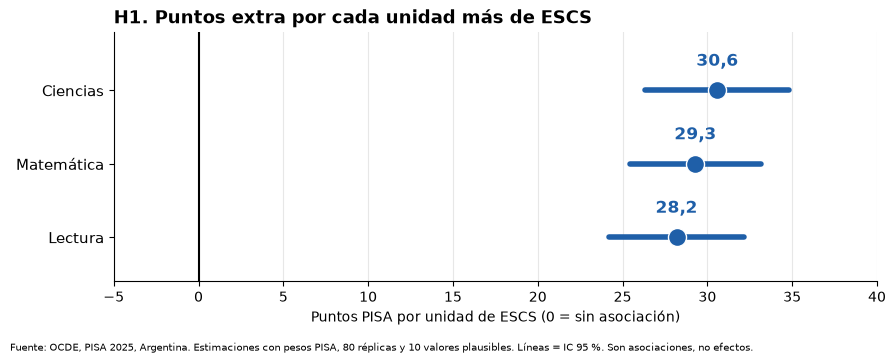

In [3]:
filas_h1 = []
for area in ["Ciencias", "Matemática", "Lectura"]:
    est, inf, sup = buscar(tabla03, "Pendiente de ESCS en " + area)
    filas_h1.append((area, est, inf, sup))

fig, ax = plt.subplots(figsize=(9, 3.6))
dibujar_puntos(ax, filas_h1, "H1. Puntos extra por cada unidad más de ESCS", "Puntos PISA por unidad de ESCS (0 = sin asociación)", 1)
ax.set_xlim(-5, 40)
fig.text(0.01, 0.01, pie, fontsize=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(carpeta_figuras / "07_h1_escs_rendimiento.png", dpi=200)
plt.show()

## 2. H2: el uso frecuente de IA según el nivel socioeconómico

Diferencia entre el cuartil de mayor y el de menor ESCS en el porcentaje que usa IA **semanal o diariamente**, en puntos porcentuales.

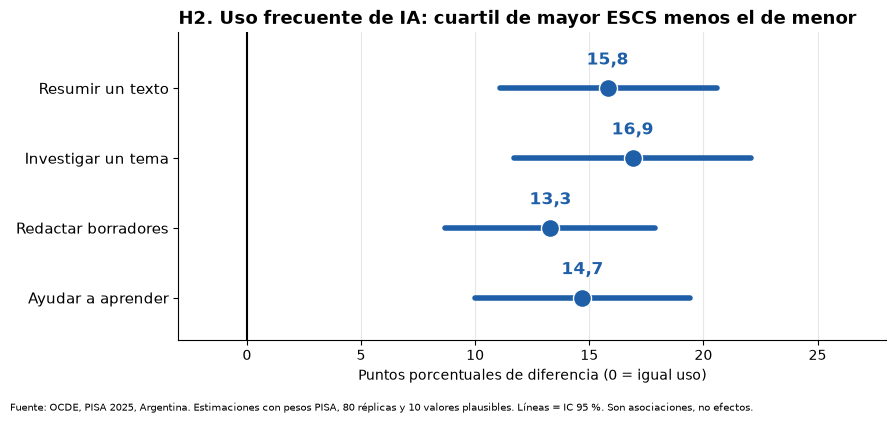

In [4]:
filas_h2 = []
for actividad in actividades:
    est, inf, sup = buscar(tabla03, actividad + ": diferencia en la proporción")
    filas_h2.append((actividad, est, inf, sup))

fig, ax = plt.subplots(figsize=(9, 4.2))
dibujar_puntos(ax, filas_h2, "H2. Uso frecuente de IA: cuartil de mayor ESCS menos el de menor", "Puntos porcentuales de diferencia (0 = igual uso)", 1, factor=100)
ax.set_xlim(-3, 28)
fig.text(0.01, 0.01, pie, fontsize=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(carpeta_figuras / "07_h2_uso_por_escs.png", dpi=200)
plt.show()

## 3. H3: el rendimiento según la frecuencia de uso de IA

Diferencia de puntaje en ciencias entre quienes usan IA **seguido** y quienes **nunca** la usan, sin ajustar. Se ve que investigar y ayudar a aprender se separan más del 0 y que redactar borradores no se distingue.

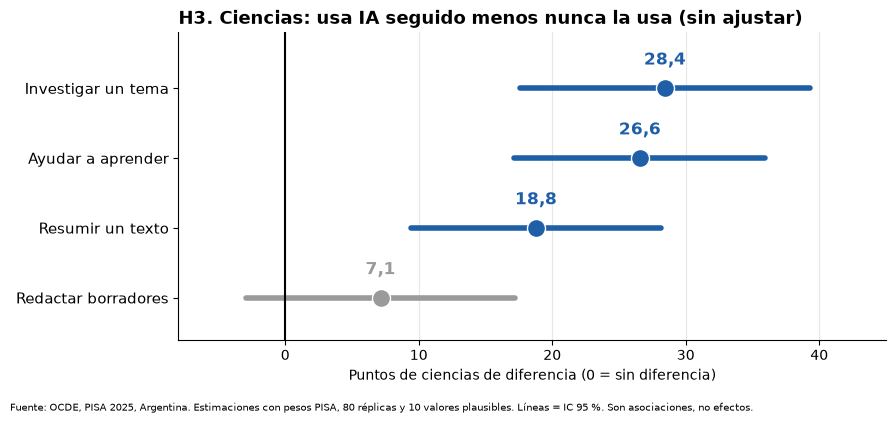

In [5]:
pares = []
for actividad in actividades:
    est, inf, sup = buscar(tabla03, actividad + ": seguido menos nunca")
    pares.append((est, actividad, inf, sup))
pares.sort(reverse=True)

filas_h3 = []
for par in pares:
    filas_h3.append((par[1], par[0], par[2], par[3]))

fig, ax = plt.subplots(figsize=(9, 4.2))
dibujar_puntos(ax, filas_h3, "H3. Ciencias: usa IA seguido menos nunca la usa (sin ajustar)", "Puntos de ciencias de diferencia (0 = sin diferencia)", 1)
ax.set_xlim(-8, 45)
fig.text(0.01, 0.01, pie, fontsize=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(carpeta_figuras / "07_h3_rendimiento_por_uso.png", dpi=200)
plt.show()

## 4. H4: cuánto de la asociación queda al controlar

La asociación entre frecuencia de IA y puntaje se reduce a menos de la mitad al ir sumando controles (primero ESCS, luego sexo y grado), pero no desaparece.

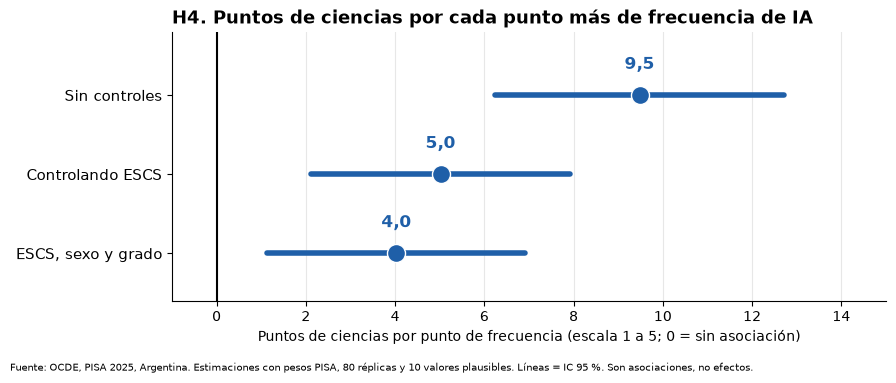

In [6]:
filas_h4 = []
for nombre, texto in [("Sin controles", "Sin controles"), ("Controlando ESCS", "Solo ESCS"), ("ESCS, sexo y grado", "ESCS, sexo y grado")]:
    est, inf, sup = buscar(tabla04, texto)
    filas_h4.append((nombre, est, inf, sup))

fig, ax = plt.subplots(figsize=(9, 3.8))
dibujar_puntos(ax, filas_h4, "H4. Puntos de ciencias por cada punto más de frecuencia de IA", "Puntos de ciencias por punto de frecuencia (escala 1 a 5; 0 = sin asociación)", 1)
ax.set_xlim(-1, 15)
fig.text(0.01, 0.01, pie, fontsize=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(carpeta_figuras / "07_h4_al_controlar.png", dpi=200)
plt.show()

## 5. Hipótesis exploratorias: HC1, HC3 y HC4

Son exploratorias (se registraron antes de calcularlas, pero después de ver los primeros resultados). HC2 no se grafica porque no se sostuvo (su intervalo incluye al 0).

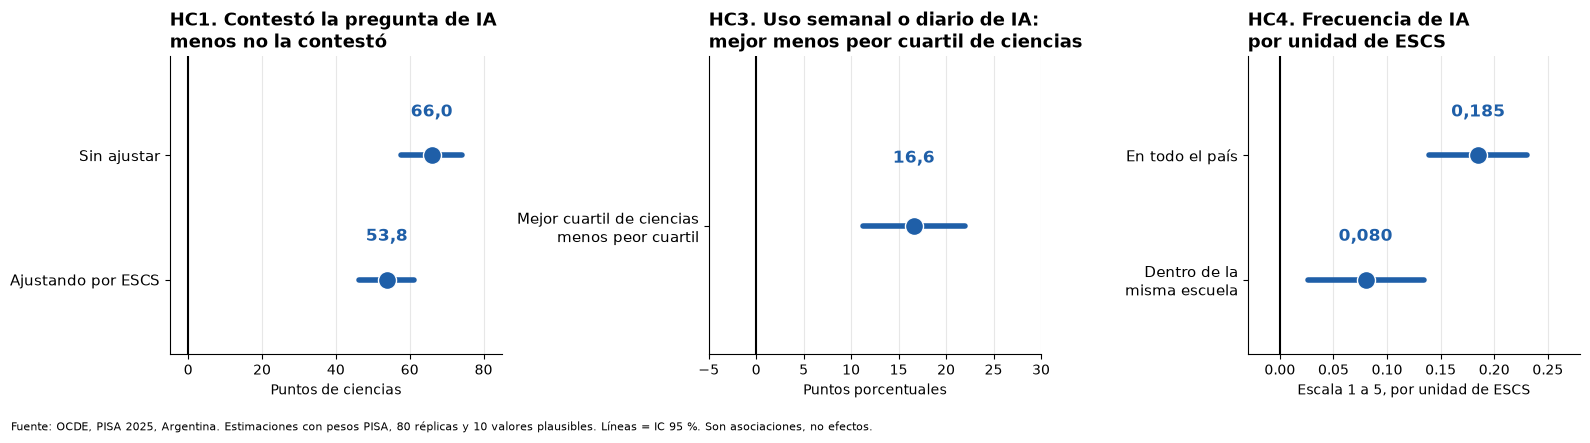

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.4))

est, inf, sup = buscar(tabla03, "Ciencias: contestó IA menos no contestó (puntos), sin ajustar")
est2, inf2, sup2 = buscar(tabla03, "Ciencias: contestó IA menos no contestó (puntos), ajustado por ESCS")
filas_hc1 = [("Sin ajustar", est, inf, sup), ("Ajustando por ESCS", est2, inf2, sup2)]
dibujar_puntos(ejes[0], filas_hc1, "HC1. Contestó la pregunta de IA\nmenos no la contestó", "Puntos de ciencias", 1)
ejes[0].set_xlim(-5, 85)

est, inf, sup = buscar(tabla05, "Proporción que usa IA semanal o diaria en alguna actividad")
filas_hc3 = [("Mejor cuartil de ciencias\nmenos peor cuartil", est, inf, sup)]
dibujar_puntos(ejes[1], filas_hc3, "HC3. Uso semanal o diario de IA:\nmejor menos peor cuartil de ciencias", "Puntos porcentuales", 1, factor=100)
ejes[1].set_xlim(-5, 30)

est, inf, sup = buscar(tabla05, "ESCS sobre frecuencia de IA, total")
est2, inf2, sup2 = buscar(tabla05, "ESCS sobre frecuencia de IA, dentro de escuela")
filas_hc4 = [("En todo el país", est, inf, sup), ("Dentro de la\nmisma escuela", est2, inf2, sup2)]
dibujar_puntos(ejes[2], filas_hc4, "HC4. Frecuencia de IA\npor unidad de ESCS", "Escala 1 a 5, por unidad de ESCS", 3)
ejes[2].set_xlim(-0.03, 0.28)

fig.text(0.01, 0.01, pie, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(carpeta_figuras / "07_exploratorias.png", dpi=200)
plt.show()

## 6. Panel resumen (una sola lámina)

Junta H1 a H4 en una figura para la presentación.

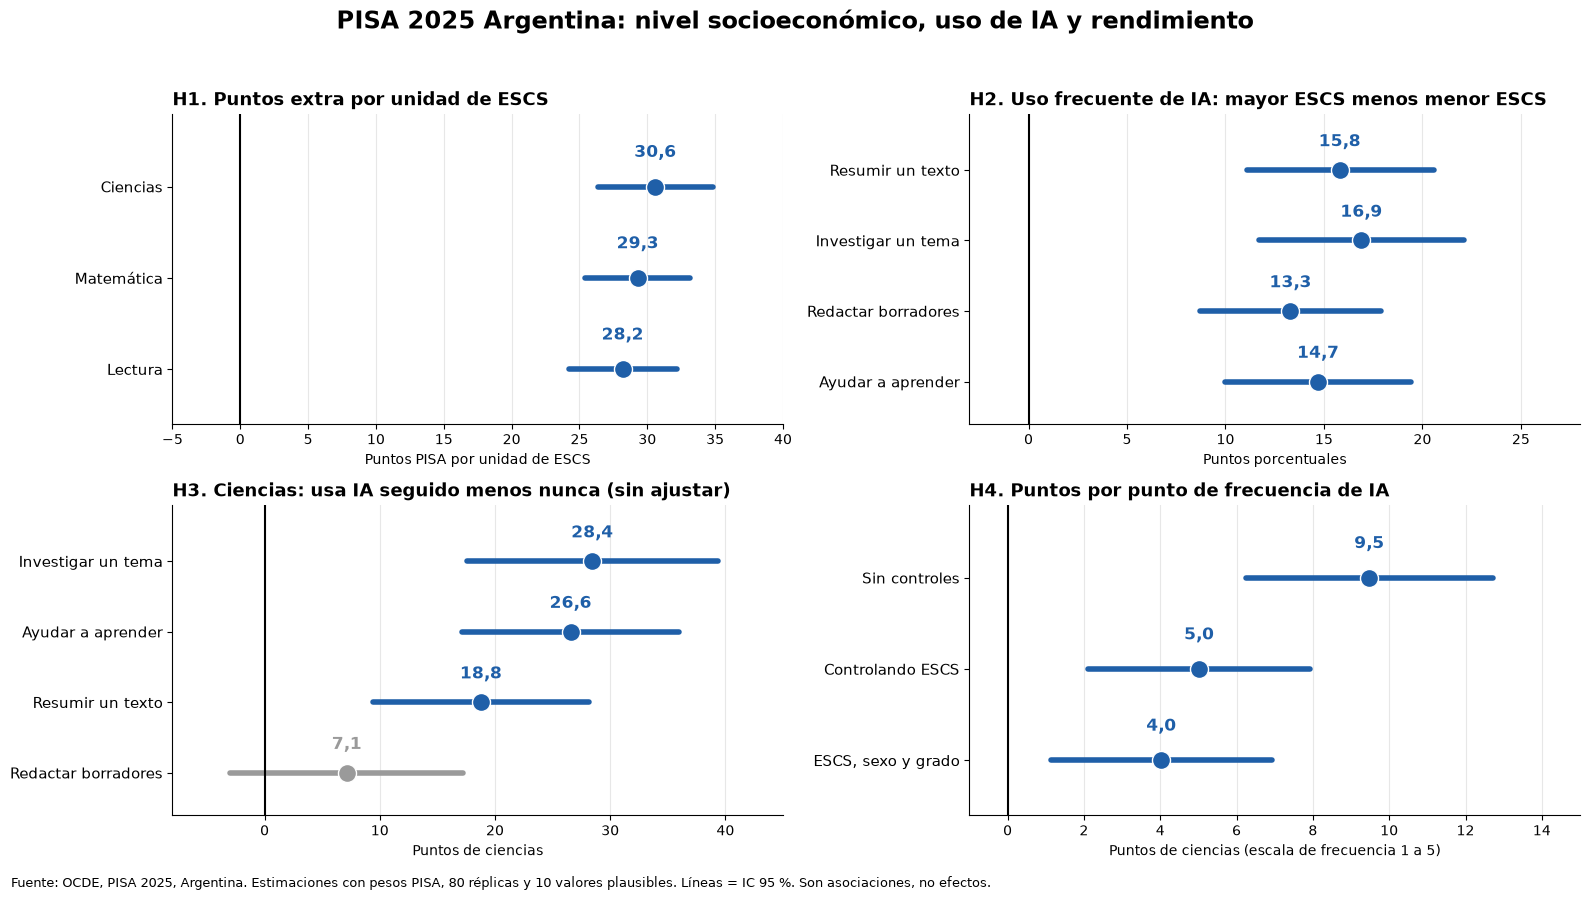

In [8]:
fig, ejes = plt.subplots(2, 2, figsize=(16, 9))

dibujar_puntos(ejes[0][0], filas_h1, "H1. Puntos extra por unidad de ESCS", "Puntos PISA por unidad de ESCS", 1)
ejes[0][0].set_xlim(-5, 40)

dibujar_puntos(ejes[0][1], filas_h2, "H2. Uso frecuente de IA: mayor ESCS menos menor ESCS", "Puntos porcentuales", 1, factor=100)
ejes[0][1].set_xlim(-3, 28)

dibujar_puntos(ejes[1][0], filas_h3, "H3. Ciencias: usa IA seguido menos nunca (sin ajustar)", "Puntos de ciencias", 1)
ejes[1][0].set_xlim(-8, 45)

dibujar_puntos(ejes[1][1], filas_h4, "H4. Puntos por punto de frecuencia de IA", "Puntos de ciencias (escala de frecuencia 1 a 5)", 1)
ejes[1][1].set_xlim(-1, 15)

fig.suptitle("PISA 2025 Argentina: nivel socioeconómico, uso de IA y rendimiento", fontsize=17, fontweight="bold")
fig.text(0.01, 0.005, pie, fontsize=9)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
fig.savefig(carpeta_figuras / "07_panel_resumen.png", dpi=200)
plt.show()

## 7. Lectura rápida

- **H1:** más ESCS, más puntaje: unos 30 puntos por unidad en las tres áreas.
- **H2:** los estudiantes de mayor ESCS usan IA con frecuencia entre 13 y 17 puntos porcentuales más, en las cuatro actividades.
- **H3:** investigar y ayudar a aprender muestran la mayor diferencia (alrededor de +27 a +28 puntos); redactar borradores no se distingue de cero.
- **H4:** al controlar por ESCS, sexo y grado la asociación baja de 9,5 a 4,0 puntos por punto de frecuencia, pero no desaparece.
- Todo es asociación: no se puede decir que la IA cause más o menos puntaje.